# Step 1: Data Exploration and Cleaning

This notebook looks at every data file before any modeling:

1. **Inventory**: what files exist, how many rows and columns each has, how much is missing.
2. **One section per source**: what the data look like (summary statistics and plots), what is missing, and how it is cleaned.
3. **Cleaning summary**: every cleaning step and how many rows it removed.
4. **The decision table**: the merged table the model uses, and which rows are dropped.
5. **Preprocessing**: how the features are standardized before modeling, and why.

All cleaning is done by the functions in `src/heatrisk/data.py` and `src/heatrisk/features.py`. This notebook also opens the raw files directly, so you can see exactly what those functions change.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from heatrisk.data import (EXTERNAL_DIR, PROJECT_ROOT, RAW_DIR, load_alerts, load_ed,
                           load_heat_alerts, load_hvi, load_mos)
from heatrisk.features import FEATURES, build_decision_table, forecast_table, high_burden_threshold

FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)

# One blue for ED visits, one orange for heat, one green for NWS alerts, used throughout
BLUE, ORANGE, GREEN, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#1f2933", "#9aa5b1", "#e4e7eb"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "font.size": 10,
    "axes.titlesize": 10, "axes.titlelocation": "left", "axes.axisbelow": True,
})

## 1. Data inventory

Every CSV in `data/raw/` and `data/external/`: rows, columns, and missing cells. A missing cell is an empty value in the file. This does **not** count days that are absent from the file altogether; those are checked separately in each section.

In [2]:
rows = []
for f in sorted(list(RAW_DIR.rglob("*.csv")) + list(EXTERNAL_DIR.rglob("*.csv"))):
    df = pd.read_csv(f, low_memory=False)
    rows.append({
        "file": str(f.relative_to(PROJECT_ROOT / "data")),
        "rows": len(df),
        "columns": df.shape[1],
        "missing cells": int(df.isna().sum().sum()),
        "% missing": round(100 * df.isna().sum().sum() / df.size, 1),
    })
inventory = pd.DataFrame(rows).set_index("file")
inventory

,rows,columns,missing cells,% missing
file,,,,
external/ehdp/heat-vulnerability-index/hvi-nta-2020.csv,198,14,0,0.0
external/ehdp/heat-vulnerability-index/hvi-nta.csv,195,15,36,1.2
external/nyc-open-data/cool_it_nyc_2020_cooling_sites.csv,271,10,258,9.5
external/nyc-open-data/cooling-locations.csv,4610,4,0,0.0
raw/ehdp/heat-syndrome/edheat1720_supp.csv,612,3,0,0.0
raw/ehdp/heat-syndrome/edheat2021_live.csv,153,3,0,0.0
raw/ehdp/heat-syndrome/edheat2022_live.csv,153,3,0,0.0
raw/ehdp/heat-syndrome/edheat2023_live.csv,153,3,0,0.0
raw/ehdp/heat-syndrome/edheat2024_live.csv,153,3,0,0.0


The MOS forecast files show many missing cells. That is expected: the files have 22 columns, and most of them (snow, precipitation type, 24-hour totals) are only filled in at certain times of day or in winter. Section 3 checks the four columns the project actually uses.

## 2. Heat-related ED visits (the outcome)

**Source:** NYC Health, syndromic surveillance. One row per day, May 1 - Sep 30.
**Columns:** `END_DATE`, `HEAT_ED_VISIT_COUNT` (suspected heat-related ED visits citywide), `MAX_DAILY_TEMP` (the higher of the heat index and the temperature at LaGuardia, F).

### 2.1 Three versions of the same days

The folder holds three overlapping versions:

* `edheat1720_supp.csv`: 2017-2020, an older supplementary file
* `edheat20XX_live.csv`: one file per year, published during that season
* `previous_years.csv`: 2017-2025, with NYC's revised 2023 case definition applied to **every** year

Using one consistent case definition matters: if the definition changed partway through, a change in counts could just reflect the new definition rather than more illness. The cell below compares the versions on the days they share.

In [3]:
folder = RAW_DIR / "ehdp/heat-syndrome"
def read_ed(name):
    df = pd.read_csv(folder / name)
    df["END_DATE"] = pd.to_datetime(df["END_DATE"], format="mixed")
    return df.set_index("END_DATE")

prev = read_ed("previous_years.csv")
versions = {"previous_years.csv": prev, "edheat1720_supp.csv": read_ed("edheat1720_supp.csv")}
for y in range(2021, 2027):
    versions[f"edheat{y}_live.csv"] = read_ed(f"edheat{y}_live.csv")

rows = []
for name, df in versions.items():
    shared = df.index.intersection(prev.index) if name != "previous_years.csv" else df.index
    diff = (df.loc[shared, "HEAT_ED_VISIT_COUNT"] - prev.loc[shared, "HEAT_ED_VISIT_COUNT"]) if len(shared) else pd.Series(dtype=float)
    rows.append({"file": name, "rows": len(df), "first day": df.index.min().date(), "last day": df.index.max().date(),
                 "days shared with previous_years": len(shared) if name != "previous_years.csv" else "",
                 "days with a different count": int((diff != 0).sum()) if name != "previous_years.csv" else "",
                 "mean difference (visits/day)": round(diff.mean(), 2) if name != "previous_years.csv" and len(shared) else ""})
pd.DataFrame(rows).set_index("file")

,rows,first day,last day,days shared with previous_years,days with a different count,mean difference (visits/day)
file,,,,,,
previous_years.csv,1367,2017-05-01,2025-09-29,,,
edheat1720_supp.csv,612,2017-05-01,2020-09-30,612,287,-0.67
edheat2021_live.csv,153,2021-05-01,2021-09-30,153,32,-0.14
edheat2022_live.csv,153,2022-05-01,2022-09-30,153,23,-0.07
edheat2023_live.csv,153,2023-05-01,2023-09-30,151,0,0.0
edheat2024_live.csv,153,2024-05-01,2024-09-30,153,0,0.0
edheat2025_live.csv,145,2025-05-01,2025-09-29,145,0,0.0
edheat2026_live.csv,153,2026-05-01,2026-09-30,0,0,


**Cleaning decision:** use `previous_years.csv` for 2017-2025 and add `edheat2026_live.csv` for 2026, the only year not yet in `previous_years.csv`. The other files are kept for reference but not used. `load_ed()` does this, renames the columns to `N` (visits) and `H` (heat), and removes any duplicate dates.

### 2.2 Missing data

Two kinds of missing data:
* **Empty cells**: a row exists but a value is blank.
* **Missing days**: a date between May 1 and Sep 30 with no row at all.

In [4]:
ed = load_ed()
print(f"Rows: {len(ed):,}   Dates: {ed.date.min().date()} to {ed.date.max().date()}")
print("Empty cells per column:", ed.isna().sum().to_dict())

expected = pd.DatetimeIndex([d for y in range(2017, 2027) for d in pd.date_range(f"{y}-05-01", f"{y}-09-30")])
missing_days = expected.difference(ed["date"])
print(f"\nExpected days: {len(expected):,}   Present: {len(ed):,}   Missing days: {len(missing_days)}")
pd.DataFrame({"missing date": missing_days.date, "weekday": missing_days.day_name()})

Rows: 1,520   Dates: 2017-05-01 to 2026-09-30
Empty cells per column: {'date': 0, 'N': 0, 'H': 0, 'season': 0}

Expected days: 1,530   Present: 1,520   Missing days: 10


,missing date,weekday
0,2023-09-29,Friday
1,2023-09-30,Saturday
2,2025-08-15,Friday
3,2025-08-18,Monday
4,2025-09-09,Tuesday
5,2025-09-19,Friday
6,2025-09-22,Monday
7,2025-09-23,Tuesday
8,2025-09-24,Wednesday
9,2025-09-30,Tuesday


**What to do with them:** nothing is filled in. These 10 days are missing from the source itself, and inventing a count would mean making up the outcome we are trying to predict. Instead, any decision row that needs a missing day (as its outcome, or as "yesterday" for a lag feature) is dropped later, in Section 7.

### 2.3 Summary statistics

In [5]:
stats = ed[["N", "H"]].describe().T
stats["skewness"] = ed[["N", "H"]].skew()
stats.index = ["N: heat ED visits per day", "H: max heat index (F)"]
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
N: heat ED visits per day,1520.0,5.01,10.87,0.0,0.75,2.0,5.0,156.0,6.81
H: max heat index (F),1520.0,81.58,9.78,49.0,75.00,82.0,88.0,108.0,-0.27


In [6]:
kappa = high_burden_threshold(ed, range(2021, 2026))
by_season = ed.groupby("season").agg(
    days=("N", "size"), mean_N=("N", "mean"), sd_N=("N", "std"), median_N=("N", "median"), max_N=("N", "max"),
    pct_zero_days=("N", lambda s: 100 * (s == 0).mean()),
    high_burden_days=("N", lambda s: int((s >= kappa).sum())),
    mean_H=("H", "mean"), sd_H=("H", "std"), days_H_95plus=("H", lambda s: int((s >= 95).sum())),
)
print(f"High-burden day = N >= {kappa:g} (90th percentile of 2021-2025)")
by_season.round(1)

High-burden day = N >= 14 (90th percentile of 2021-2025)


,days,mean_N,sd_N,median_N,max_N,pct_zero_days,high_burden_days,mean_H,sd_H,days_H_95plus
season,,,,,,,,,,
2017,153,3.5,6.7,1.0,39,37.3,9,80.7,9.6,10
2018,153,5.6,8.8,2.0,56,20.9,19,83.9,9.5,24
2019,153,5.4,13.8,2.0,112,26.8,11,81.9,9.8,9
2020,153,3.1,4.9,1.0,24,32.7,9,82.7,10.0,19
2021,153,4.3,8.5,1.0,65,26.1,15,82.5,9.5,16
2022,153,4.8,7.7,2.0,37,26.8,18,80.8,9.7,10
2023,151,3.3,5.3,1.0,28,34.4,7,79.7,9.4,8
2024,153,5.1,8.4,2.0,51,19.6,19,80.8,9.6,14
2025,145,7.6,17.1,2.0,141,12.4,22,80.3,10.1,11


**What the numbers say**

* **N is heavily right-skewed.** The median day has about 2 visits, but the mean is higher and the standard deviation is larger than the mean, because a few heat-wave days have 50-150 visits. The mean alone is misleading here, which is why the project predicts *high-burden days* rather than the average.
* **Many days have zero visits,** mostly cool days in May and September.
* **2025-2026 run higher** than earlier years even though their heat is similar. This may be hotter summers, or a change in reporting. It is flagged as an open question, and the season-by-season validation in Step 2 shows whether it affects the model.

### 2.4 Plots

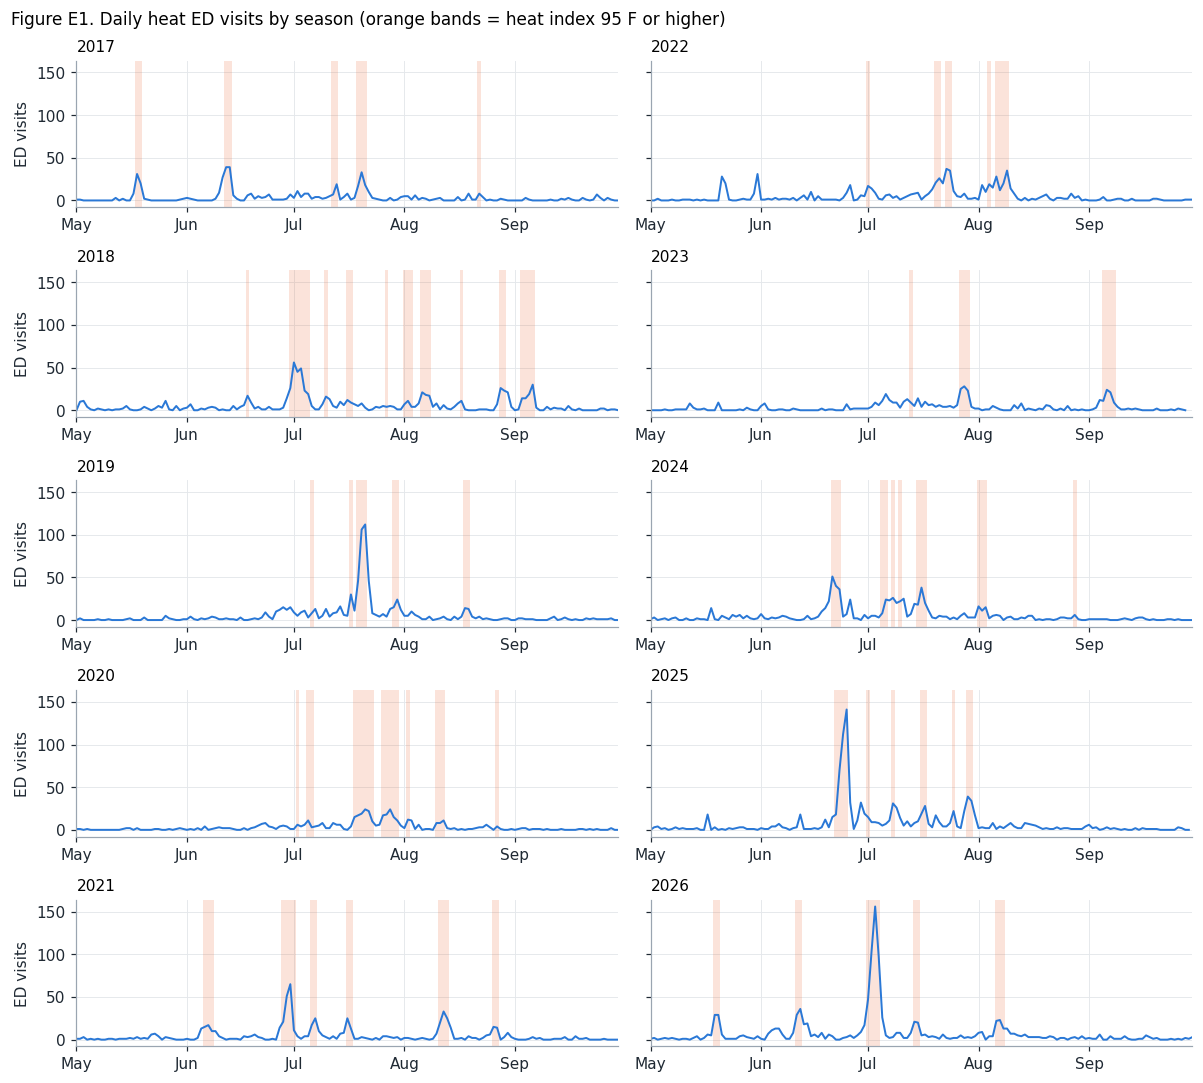

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(11, 10), sharey=True)
for ax, (season, g) in zip(axes.T.flat, ed.groupby("season")):
    hot = g[g["H"] >= 95]
    for day in hot["date"]:
        ax.axvspan(day - pd.Timedelta(hours=12), day + pd.Timedelta(hours=12), color=ORANGE, alpha=0.18, lw=0)
    ax.plot(g["date"], g["N"], color=BLUE, lw=1.3)
    ax.set_title(str(season))
    ax.set_xlim(pd.Timestamp(f"{season}-05-01"), pd.Timestamp(f"{season}-09-30"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
for ax in axes[:, 0]:
    ax.set_ylabel("ED visits")
fig.suptitle("Figure E1. Daily heat ED visits by season (orange bands = heat index 95 F or higher)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "eda1_daily_ed_by_season.png")
plt.show()

Spikes line up with the orange (95 F+) days, and the biggest spikes come when several hot days run together. Seasons differ a lot: 2021 has a few sharp spikes, while 2025 has a large June heat wave.

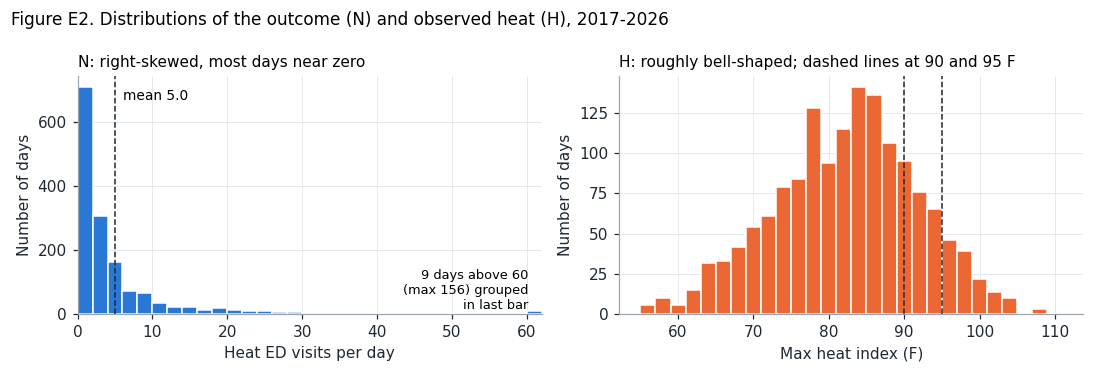

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.hist(ed["N"].clip(upper=61), bins=np.arange(0, 64, 2), color=BLUE, edgecolor="white")
a1.set_xlim(0, 62)
a1.annotate(f"{(ed['N'] > 60).sum()} days above 60\n(max {ed['N'].max()}) grouped\nin last bar",
            (61, 15), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=8.5)
a1.axvline(ed["N"].mean(), color=INK, lw=1, ls="--")
a1.annotate(f"mean {ed['N'].mean():.1f}", (ed["N"].mean(), a1.get_ylim()[1] * 0.9), xytext=(5, 0),
            textcoords="offset points", fontsize=9)
a1.set_xlabel("Heat ED visits per day"); a1.set_ylabel("Number of days")
a1.set_title("N: right-skewed, most days near zero")
a2.hist(ed["H"], bins=np.arange(55, 112, 2), color=ORANGE, edgecolor="white")
for x in (90, 95):
    a2.axvline(x, color=INK, lw=1, ls="--")
a2.set_xlabel("Max heat index (F)"); a2.set_ylabel("Number of days")
a2.set_title("H: roughly bell-shaped; dashed lines at 90 and 95 F")
fig.suptitle("Figure E2. Distributions of the outcome (N) and observed heat (H), 2017-2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "eda2_distributions.png")
plt.show()

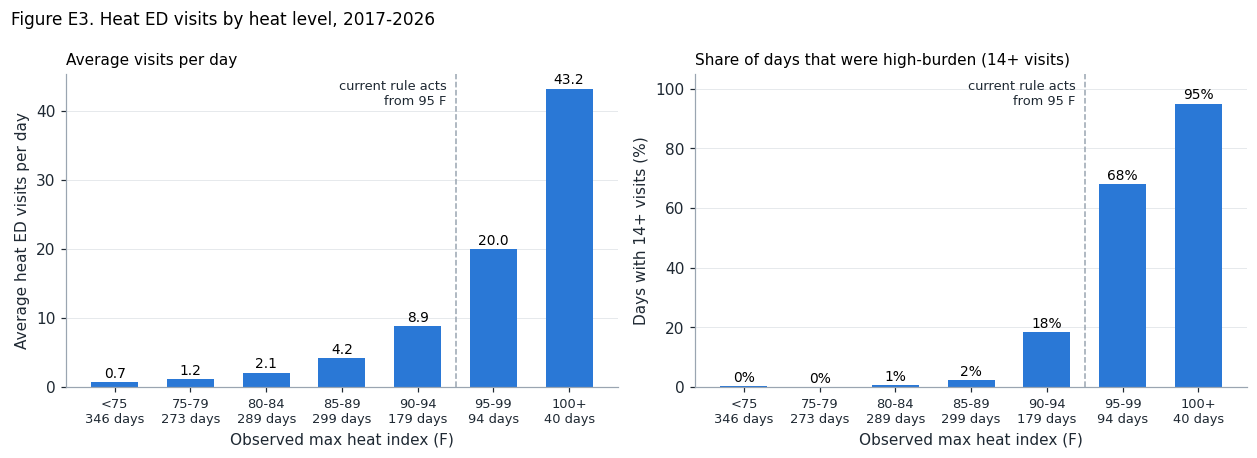

,days,mean,median,q25,q75,pct_high_burden
heat_band,,,,,,
<75,346,0.7,0.0,0.0,1.0,0.3
75-79,273,1.2,1.0,0.0,2.0,0.0
80-84,289,2.1,1.0,1.0,3.0,0.7
85-89,299,4.2,4.0,2.0,6.0,2.3
90-94,179,8.9,7.0,4.0,12.0,18.4
95-99,94,20.0,17.0,11.2,24.0,68.1
100+,40,43.2,30.0,22.0,49.5,95.0


In [9]:
BANDS = [0, 75, 80, 85, 90, 95, 100, 130]
BAND_LABELS = ["<75", "75-79", "80-84", "85-89", "90-94", "95-99", "100+"]
ed["heat_band"] = pd.cut(ed["H"], BANDS, right=False, labels=BAND_LABELS)
by_band = ed.groupby("heat_band", observed=True)["N"].agg(
    days="size", mean="mean", median="median",
    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
    pct_high_burden=lambda s: 100 * (s >= kappa).mean())

x = np.arange(len(by_band))
ticks = [f"{b}\n{n} days" for b, n in zip(by_band.index, by_band["days"])]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Left: average visits, with the middle half of days as a line
a1.bar(x, by_band["mean"], color=BLUE, width=0.62)
for xi, m in zip(x, by_band["mean"]):
    a1.annotate(f"{m:.1f}", (xi, m), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
a1.set_ylabel("Average heat ED visits per day")
a1.set_title("Average visits per day")

# Right: chance that a day is high-burden
a2.bar(x, by_band["pct_high_burden"], color=BLUE, width=0.62)
for xi, v in zip(x, by_band["pct_high_burden"]):
    a2.annotate(f"{v:.0f}%", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
a2.set_ylim(0, 105)
a2.set_ylabel("Days with 14+ visits (%)")
a2.set_title(f"Share of days that were high-burden ({kappa:g}+ visits)")

for ax in (a1, a2):
    ax.set_xticks(x, ticks, fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("Observed max heat index (F)")
    ax.axvline(4.5, color=MUTED, lw=1, ls="--")   # boundary between 90-94 and 95+
    ax.annotate("current rule acts\nfrom 95 F", (4.5, ax.get_ylim()[1]), xytext=(-6, -4),
                textcoords="offset points", ha="right", va="top", fontsize=8.5, color=INK)
fig.suptitle("Figure E3. Heat ED visits by heat level, 2017-2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "eda3_ed_vs_heat.png")
plt.show()

by_band.round(1)

**How to read Figure E3.** Each bar groups all days whose observed heat index fell in that 5 F band; the number of days is under each label.

* **Left:** average visits per day.
* **Right:** the share of those days that were high-burden. This is the chart that matters for the decision.

**What it shows.** Below 85 F, almost no day is high-burden. At **90-94 F, about 1 in 5 days is high-burden**, yet the current rule does not act until 95 F. From 95 F up, most days are high-burden. Average visits roughly double with every 5 F step.

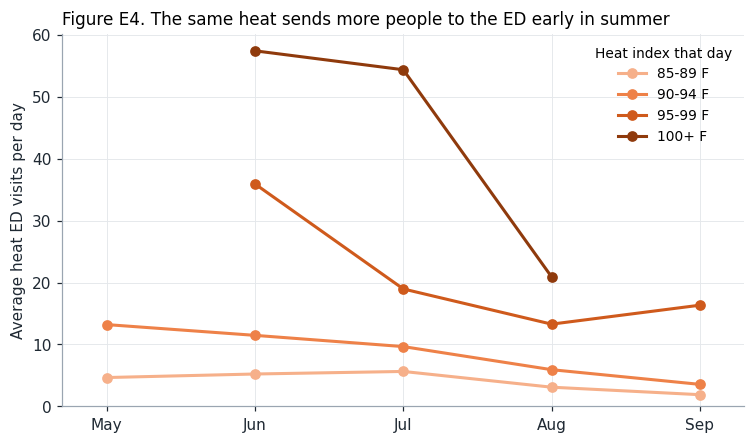

Average visits per day (rows: heat band, columns: month); number of days in brackets


month,May,Jun,Jul,Aug,Sep
heat_band,,,,,
85-89,4.6 (17),5.2 (55),5.6 (95),3.1 (91),1.9 (41)
90-94,13.2 (10),11.5 (39),9.6 (71),5.9 (48),3.5 (11)
95-99,-,35.9 (12),19.0 (50),13.3 (22),16.3 (6)
100+,-,57.4 (7),54.4 (19),20.9 (12),-


In [10]:
ed["month"] = ed["date"].dt.month
MONTHS = {5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep"}
hot_bands = ["85-89", "90-94", "95-99", "100+"]
cell = (ed[ed["heat_band"].isin(hot_bands)]
        .groupby(["heat_band", "month"], observed=True)["N"].agg(["mean", "size"]).reset_index())
cell = cell[cell["size"] >= 5]          # hide averages based on fewer than 5 days

shades = {"85-89": "#f6b08a", "90-94": "#ee8148", "95-99": "#cf5a1c", "100+": "#8f3a0c"}  # light = cooler, dark = hotter
fig, ax = plt.subplots(figsize=(8, 4.4))
for band in hot_bands:
    g = cell[cell["heat_band"] == band]
    ax.plot(g["month"], g["mean"], color=shades[band], marker="o", markersize=6, lw=2, label=f"{band} F")
ax.set_xticks(list(MONTHS), list(MONTHS.values()))
ax.set_xlim(4.7, 9.3)
ax.set_ylim(0, None)
ax.set_ylabel("Average heat ED visits per day")
ax.legend(frameon=False, title="Heat index that day", loc="upper right", fontsize=9, title_fontsize=9)
ax.set_title("Figure E4. The same heat sends more people to the ED early in summer", fontsize=11)
fig.savefig(FIG / "eda4_ed_by_month.png")
plt.show()

print("Average visits per day (rows: heat band, columns: month); number of days in brackets")
tbl = cell.assign(txt=lambda c: c["mean"].round(1).astype(str) + " (" + c["size"].astype(str) + ")")
tbl.pivot(index="heat_band", columns="month", values="txt").rename(columns=MONTHS).fillna("-")

**How to read Figure E4.** Each line is one heat band, and each point is the average number of visits on days in that band during that month. Points based on fewer than 5 days are left out because they are too noisy.

**What it shows.** At the same heat, June days send about two to three times as many people to the ED as August days (for example, 11.5 vs. 5.9 visits at 90-94 F, and 57 vs. 21 at 100 F+). July falls in between. A likely reason is that people have not yet adjusted to the heat early in the summer. This is why the model includes **day of season**: a fixed temperature rule treats a 93 F day in June the same as one in August, but the risk is not the same.

**The ten highest days:**

In [11]:
ed.nlargest(10, "N")[["date", "N", "H"]].reset_index(drop=True)

,date,N,H
0,2026-07-03,156,108
1,2025-06-25,141,98
2,2019-07-21,112,107
3,2025-06-24,112,100
4,2019-07-20,106,104
5,2026-07-02,104,108
6,2026-07-04,97,104
7,2025-06-23,70,103
8,2021-06-30,65,100
9,2018-07-01,56,100


**Outliers are kept.** The extreme days are real heat waves, not data errors, and they are exactly what the city needs to catch. Removing them would remove the signal.

## 3. NWS MOS forecasts (the model inputs)

**Source:** Iowa Environmental Mesonet archive of the NWS extended MOS (MEX) forecast for LaGuardia. Each forecast **run** (issued at 00 and 12 UTC each day) predicts conditions at many future **valid times** over the next week.

**Columns used:**
* `runtime`: when the forecast was issued (UTC). This is the decision time.
* `ftime`: the time being forecast (UTC).
* `n_x`: forecast max temperature (on daytime rows) or min temperature (on nighttime rows), F.
* `dpt`: forecast dewpoint, F, used with `n_x` to compute a forecast heat index.

The other 18 columns (wind, clouds, precipitation, snow) are not used.

In [12]:
mos = load_mos()
used = ["runtime", "ftime", "n_x", "dpt"]
print(f"Rows: {len(mos):,}   Forecast runs: {mos['runtime'].nunique():,}   "
      f"Issued {mos.runtime.min():%Y-%m-%d} to {mos.runtime.max():%Y-%m-%d}")
print("\nEmpty cells in the columns we use:")
print(mos[used].isna().sum().to_string())
print("\nRows per file:")
print(mos.groupby(mos["runtime"].dt.year).size().to_string())

Rows: 27,480   Forecast runs: 1,832   Issued 2021-05-01 to 2026-09-30

Empty cells in the columns we use:
runtime    0
ftime      0
n_x        0
dpt        0

Rows per file:
runtime
2021    4590
2022    4590
2023    4560
2024    4590
2025    4575
2026    4575


`n_x` is blank on some rows because MOS only reports a max or min temperature at 00 and 12 UTC. Every other valid time has no `n_x` by design. Those rows are not used, so these blanks are not a problem. The check that matters is whether any **forecast runs** are missing:

In [13]:
runs = mos.drop_duplicates("runtime")["runtime"]
rows = []
for y in sorted(runs.dt.year.unique()):
    expected_runs = pd.date_range(f"{y}-05-01", f"{y}-09-30 12:00", freq="12h", tz="UTC")
    missing_runs = expected_runs.difference(runs)
    rows.append({"season": y, "expected runs": len(expected_runs), "missing runs": len(missing_runs),
                 "which": ", ".join(f"{m:%b %d %H}Z" for m in missing_runs) or "-"})
pd.DataFrame(rows).set_index("season")

,expected runs,missing runs,which
season,,,
2021,306,0,-
2022,306,0,-
2023,306,2,"Jun 06 12Z, Jun 07 00Z"
2024,306,0,-
2025,306,1,Aug 08 00Z
2026,306,1,Sep 20 00Z


A few runs are missing (the archive's gaps, not ours). If the 12 UTC run is missing on a given morning, there is no decision row for that morning. Section 7 shows how many rows this removes.

### 3.1 Turning forecasts into one number per day

`forecast_table()` keeps only the 12 UTC runs (8 a.m. in New York, the decision time) and the daytime-max rows, converts times to New York time, and computes the forecast heat **F = max(heat index, temperature)**, the same definition the ED file uses for observed heat H. The result is one row per (decision day, forecast day).

In [14]:
fc = forecast_table(mos)
print(f"Daily forecasts: {len(fc):,} rows | leads available: {sorted(fc['lead'].unique())}")
fc.groupby("lead")["F"].describe().round(1)

Daily forecasts: 6,419 rows | leads available: [1, 2, 3, 4, 5, 6, 7]


,count,mean,std,min,25%,50%,75%,max
lead,,,,,,,,
1,917.0,81.1,10.0,51.0,75.0,82.0,87.8,107.3
2,917.0,81.1,9.9,54.0,75.0,81.8,88.0,109.4
3,917.0,81.2,9.4,53.0,75.0,82.0,87.5,109.7
4,917.0,81.2,9.2,56.0,75.0,81.6,87.2,107.2
5,917.0,80.8,8.4,56.0,75.0,81.4,86.1,108.9
6,917.0,81.1,8.3,59.0,75.1,81.4,86.8,103.1
7,917.0,81.3,7.7,59.0,76.0,82.0,86.3,108.1


### 3.2 How accurate are the forecasts?

The model only sees the forecast, so it matters how far off the forecast is. The comparison below matches each forecast to the heat that was actually observed that day.

In [15]:
obs = ed.set_index("date")["H"]
fc["H_obs"] = obs.reindex(fc["s"]).values
fc["error"] = fc["F"] - fc["H_obs"]
acc = fc.dropna(subset=["H_obs"]).groupby("lead")["error"].agg(
    days="size", mean_error="mean", sd_error="std", mean_abs_error=lambda e: e.abs().mean())
acc.round(2)

,days,mean_error,sd_error,mean_abs_error
lead,,,,
1,901,0.05,3.58,2.72
2,895,-0.01,3.76,2.89
3,889,0.02,4.03,3.08
4,883,-0.05,4.50,3.50
5,877,-0.55,5.28,4.04
6,871,-0.22,5.72,4.42
7,865,0.01,6.13,4.69


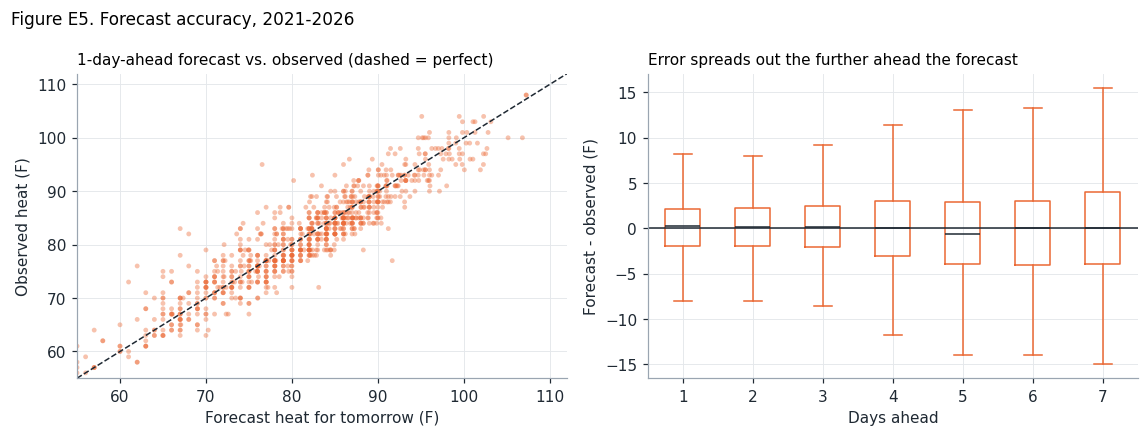

Near the decision range (forecast 88-100 F, n = 202): mean error +1.0 F, mean absolute error 2.6 F


In [16]:
lead1 = fc[(fc["lead"] == 1)].dropna(subset=["H_obs"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4))
a1.scatter(lead1["F"], lead1["H_obs"], s=10, color=ORANGE, alpha=0.4, edgecolor="none")
lims = [55, 112]
a1.plot(lims, lims, color=INK, lw=1, ls="--")
a1.set_xlim(lims); a1.set_ylim(lims)
a1.set_xlabel("Forecast heat for tomorrow (F)"); a1.set_ylabel("Observed heat (F)")
a1.set_title("1-day-ahead forecast vs. observed (dashed = perfect)")
leads = sorted(acc.index)
a2.boxplot([fc.loc[(fc["lead"] == L), "error"].dropna() for L in leads], showfliers=False,
           medianprops={"color": INK}, boxprops={"color": ORANGE}, whiskerprops={"color": ORANGE}, capprops={"color": ORANGE})
a2.set_xticks(range(1, len(leads) + 1), leads)
a2.axhline(0, color=INK, lw=1)
a2.set_xlabel("Days ahead"); a2.set_ylabel("Forecast - observed (F)")
a2.set_title("Error spreads out the further ahead the forecast")
fig.suptitle("Figure E5. Forecast accuracy, 2021-2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "eda5_forecast_accuracy.png")
plt.show()

near = lead1[lead1["F"].between(88, 100)]
print(f"Near the decision range (forecast 88-100 F, n = {len(near)}): mean error {near['error'].mean():+.1f} F, "
      f"mean absolute error {near['error'].abs().mean():.1f} F")

## 4. NWS alerts (what NYC actually did)

**Source:** Iowa Environmental Mesonet archive of every NWS watch, warning and advisory for zone NYZ072 (Manhattan). Heat alerts are issued for all five boroughs together, so one zone is enough.

### 4.1 Raw contents

In [17]:
alerts = load_alerts()
print(f"Rows: {len(alerts)}   Years: {alerts.vtec_year.min()}-{alerts.vtec_year.max()}")
print("Empty cells per column:", {k: v for k, v in alerts.isna().sum().items() if v})
alerts["name"].value_counts().head(12).to_frame("alerts")

Rows: 472   Years: 2017-2026
Empty cells per column: {'hvtec_nwsli': 401}


,alerts
name,
Wind Advisory,78
Coastal Flood Statement,52
Coastal Flood Advisory,50
Heat Advisory,49
Winter Weather Advisory,38
Flood Watch,36
Flash Flood Watch,35
Dense Fog Advisory,22
Winter Storm Watch,16


`hvtec_nwsli` is empty for every row because it is only used for river-flood alerts, so it can be ignored.

### 4.2 Cleaning: from all alerts to heat alerts that took effect

Each step below is one rule in `load_heat_alerts()`.

In [18]:
from heatrisk.data import HEAT_PHENOMENA
step0 = alerts
step1 = step0[step0["phenomena"].isin(HEAT_PHENOMENA)]
step2 = step1[step1["significance"] != "A"]
step3 = step2[step2["expired"] > step2["issued"]]
step4 = step3.drop_duplicates(["vtec_year", "phenomena", "significance", "eventid"])
funnel = pd.DataFrame({
    "rows left": [len(step0), len(step1), len(step2), len(step3), len(step4)],
    "why": ["all alerts for Manhattan, any hazard",
            "keep heat products only (HT, EH, XH)",
            "drop watches: a heads-up that a warning may follow, not an activation",
            "drop alerts that expired before they started (cancelled or upgraded)",
            "drop duplicate copies of the same alert"],
}, index=["raw", "heat only", "no watches", "not cancelled", "no duplicates"])
funnel["removed"] = -funnel["rows left"].diff().fillna(0).astype(int)
heat_alerts = load_heat_alerts()
assert len(heat_alerts) == len(step4)
funnel[["rows left", "removed", "why"]]

,rows left,removed,why
raw,472,0,"all alerts for Manhattan, any hazard"
heat only,61,411,"keep heat products only (HT, EH, XH)"
no watches,56,5,drop watches: a heads-up that a warning may fo...
not cancelled,53,3,drop alerts that expired before they started (...
no duplicates,53,0,drop duplicate copies of the same alert


In [19]:
heat_alerts["hours"] = (heat_alerts["expired"] - heat_alerts["issued"]).dt.total_seconds() / 3600
summary = heat_alerts.groupby("vtec_year").agg(alerts=("product", "size"), total_hours=("hours", "sum"))
summary = summary.join(heat_alerts.groupby(["vtec_year", "product"]).size().unstack(fill_value=0))
print(f"Alert length: mean {heat_alerts.hours.mean():.0f} h, sd {heat_alerts.hours.std():.0f} h")
summary

Alert length: mean 41 h, sd 27 h


,alerts,total_hours,Extreme Heat Warning,Heat Advisory
vtec_year,,,,
2017,4,96.416667,0,4
2018,8,411.400000,1,7
2019,5,135.650000,1,4
2020,5,164.916667,0,5
2021,5,256.133333,1,4
2022,5,228.233333,0,5
2023,3,134.700000,1,2
2024,6,287.000000,0,6
2025,6,186.850000,1,5


### 4.3 Alert days vs. what happened

This puts the alerts on the same timeline as ED visits for the seasons with forecasts (2021-2026). The question: which high-burden days had **no** alert?

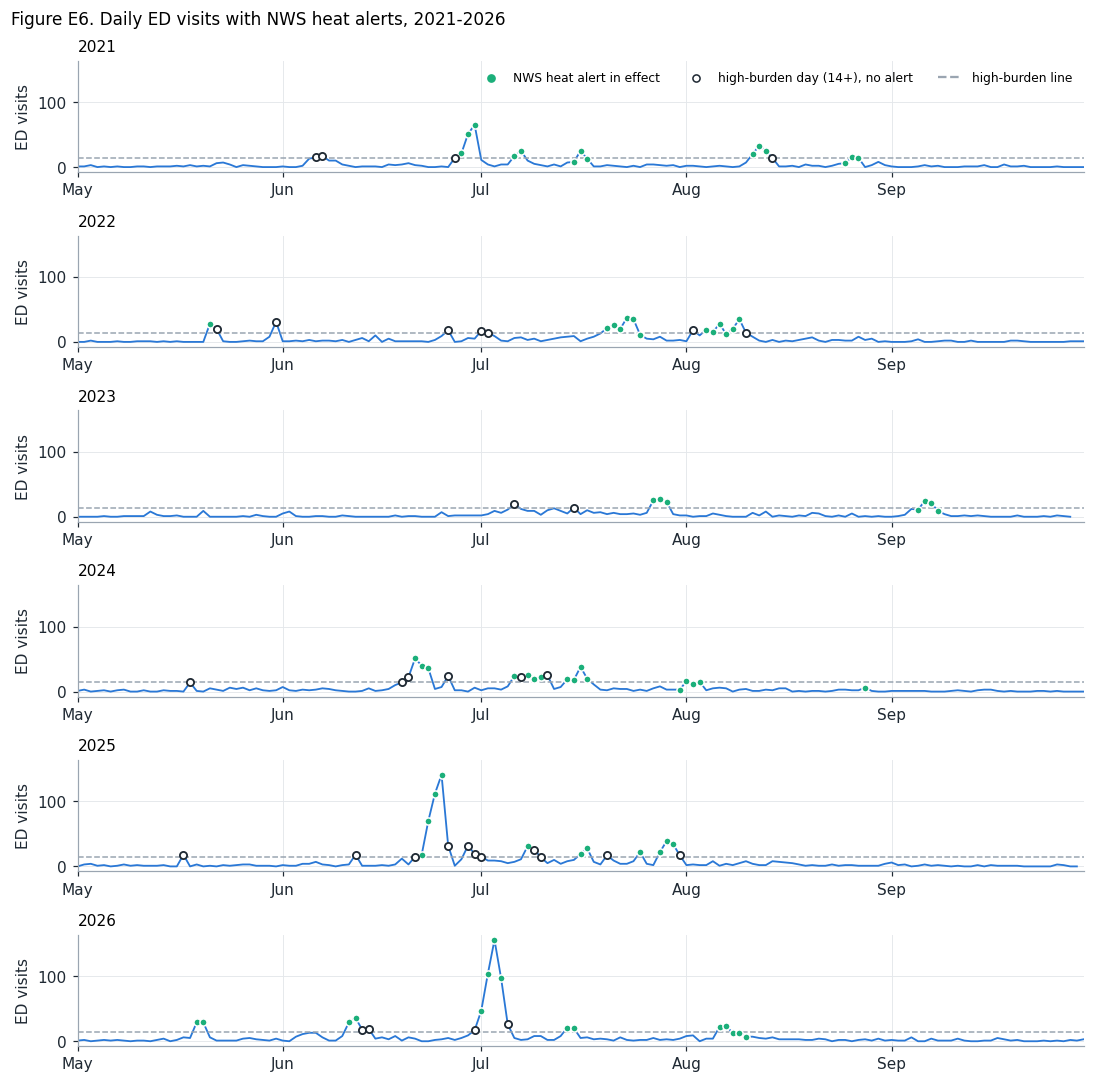

High-burden days with no alert: 34
  by heat that day: {'<90 F': 9, '90-94 F': 21, '95-99 F': 4, '100+ F': 0}
  by month: {'Jun': 15, 'Jul': 12, 'May': 4, 'Aug': 3}


alert,alert,no alert,All
high_burden,,,
high-burden day,63,34,97
normal day,13,798,811
All,76,832,908


In [20]:
from heatrisk.features import alert_in_effect
e21 = ed[ed["season"] >= 2021].copy()
e21["alert"] = alert_in_effect(pd.DatetimeIndex(e21["date"]), heat_alerts)
e21["high_burden"] = e21["N"] >= kappa

fig, axes = plt.subplots(6, 1, figsize=(10, 10), sharey=True)
for ax, (season, g) in zip(axes, e21.groupby("season")):
    ax.plot(g["date"], g["N"], color=BLUE, lw=1.2)
    ax.axhline(kappa, color=MUTED, lw=1, ls="--")
    a = g[g["alert"] == 1]
    ax.scatter(a["date"], a["N"], s=22, color=GREEN, zorder=3, edgecolor="white", linewidth=1)
    m = g[(g["alert"] == 0) & g["high_burden"]]
    ax.scatter(m["date"], m["N"], s=22, facecolor="white", edgecolor=INK, linewidth=1.2, zorder=3)
    ax.set_title(str(season)); ax.set_ylabel("ED visits")
    ax.set_xlim(pd.Timestamp(f"{season}-05-01"), pd.Timestamp(f"{season}-09-30"))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
axes[0].scatter([], [], s=22, color=GREEN, label="NWS heat alert in effect")
axes[0].scatter([], [], s=22, facecolor="white", edgecolor=INK, label=f"high-burden day ({kappa:g}+), no alert")
axes[0].plot([], [], color=MUTED, ls="--", label="high-burden line")
axes[0].legend(frameon=False, loc="upper right", fontsize=8, ncol=3)
fig.suptitle("Figure E6. Daily ED visits with NWS heat alerts, 2021-2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "eda6_alerts_vs_ed.png")
plt.show()

missed = e21[e21["high_burden"] & (e21["alert"] == 0)]
print(f"High-burden days with no alert: {len(missed)}")
print("  by heat that day:", pd.cut(missed["H"], [0, 90, 95, 100, 120], right=False,
      labels=["<90 F", "90-94 F", "95-99 F", "100+ F"]).value_counts().sort_index().to_dict())
print("  by month:", missed["date"].dt.month.map({5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep"}).value_counts().to_dict())
ct = pd.crosstab(e21["high_burden"].map({True: "high-burden day", False: "normal day"}),
                 e21["alert"].map({1: "alert", 0: "no alert"}), margins=True)
ct

The hollow circles are the cases the project is about: dangerous days the current system did not flag. About a third of high-burden days had no alert. Most of those had a heat index of 90-94 F, just under the alert criteria, and most fell in June and July. A few are the day right after a heat wave, when visits stay high even though it has cooled down.

## 5. Heat Vulnerability Index (used later, for "where")

One row per neighborhood (2020 NTA boundaries). `HVI_RANK` runs from 1 (least vulnerable) to 5 (most). It is used in a later step to decide which neighborhoods to focus on, not in the model.

In [21]:
hvi = load_hvi()
print(f"Rows: {len(hvi)}   Empty cells: {int(hvi.isna().sum().sum())}")
hvi[["HVI_RANK", "SURFACE_TEMP", "MEDIAN_INCOME", "GREENSPACE", "PCT_HOUSEHOLDS_AC"]].describe().round(1)

Rows: 198   Empty cells: 0


,HVI_RANK,SURFACE_TEMP,MEDIAN_INCOME,GREENSPACE,PCT_HOUSEHOLDS_AC
count,198.0,198.0,198.0,198.0,198.0
mean,3.0,86.8,74591.1,27.8,90.6
std,1.4,2.0,33938.0,12.0,4.9
min,1.0,80.8,24474.0,3.9,75.8
25%,2.0,85.3,51684.6,19.6,87.8
50%,3.0,87.0,69854.2,25.0,91.9
75%,4.0,88.2,89370.2,34.3,94.1
max,5.0,90.8,208844.0,73.9,98.4


In [22]:
hvi["HVI_RANK"].value_counts().sort_index().to_frame("neighborhoods")

,neighborhoods
HVI_RANK,
1,37
2,40
3,40
4,41
5,40


## 6. Cooling-site files (not used)

`data/external/nyc-open-data/` holds NYC Parks **outdoor** cooling features (misting stations, spray showers, drinking fountains). They are not indoor cooling centers, so they are not used in the model. They are kept only for reference.

In [23]:
for f in sorted((EXTERNAL_DIR / "nyc-open-data").glob("*.csv")):
    df = pd.read_csv(f)
    print(f"{f.name}: {len(df):,} rows, columns = {list(df.columns)}")

cool_it_nyc_2020_cooling_sites.csv: 271 rows, columns = ['Status', 'FeatureType', 'PropertyName', 'SubPropertyName', 'GISPropNum', 'OMPPropID', 'Borough', 'District', 'x', 'y']
cooling-locations.csv: 4,610 rows, columns = ['PropName', 'Borough', 'System', 'Type of Water Feature']


## 7. Cleaning summary and the decision table

### 7.1 Every cleaning step

In [24]:
pd.DataFrame([
    ["ED visits", "use previous_years.csv + 2026 live file", "older versions of the same days ignored",
     "one consistent case definition"],
    ["ED visits", "drop duplicate dates", "0 rows", "safety check"],
    ["ED visits", "missing days are not filled in", f"{len(missing_days)} days absent in source",
     "inventing counts would invent the outcome"],
    ["ED visits", "keep extreme days", "0 rows", "they are real heat waves, not errors"],
    ["Forecasts", "keep 12 UTC runs, daytime-max rows", "other rows not needed", "8 a.m. decision time"],
    ["Forecasts", "convert UTC to New York time", "-", "so days line up with the ED data"],
    ["Forecasts", "compute heat index from n_x and dpt", "-", "same definition as observed H"],
    ["Alerts", "heat only, no watches, no cancelled, no duplicates", f"{len(alerts)} -> {len(heat_alerts)} rows",
     "keep only real activations"],
], columns=["source", "step", "effect", "why"])

,source,step,effect,why
0,ED visits,use previous_years.csv + 2026 live file,older versions of the same days ignored,one consistent case definition
1,ED visits,drop duplicate dates,0 rows,safety check
2,ED visits,missing days are not filled in,10 days absent in source,inventing counts would invent the outcome
3,ED visits,keep extreme days,0 rows,"they are real heat waves, not errors"
4,Forecasts,"keep 12 UTC runs, daytime-max rows",other rows not needed,8 a.m. decision time
5,Forecasts,convert UTC to New York time,-,so days line up with the ED data
6,Forecasts,compute heat index from n_x and dpt,-,same definition as observed H
7,Alerts,"heat only, no watches, no cancelled, no duplic...",472 -> 53 rows,keep only real activations


### 7.2 Building the decision table, and which rows are dropped

`build_decision_table()` makes one row per decision morning *t* (about target day *s* = *t* + 1). The cell below rebuilds it without the final drop step, so you can see how many rows are lost and why.

In [25]:
d = build_decision_table(ed, mos, heat_alerts, lead=1)

# Count, for every in-season morning with a forecast, which piece of information is missing
fc_wide = fc.pivot_table(index="t", columns="lead", values="F")
cal = pd.date_range(ed["date"].min(), ed["date"].max())
N = ed.set_index("date")["N"].reindex(cal)
mornings = pd.DatetimeIndex([t for t in fc_wide.index
                             if (t.month, t.day) >= (5, 1) and (t + pd.Timedelta(days=1)).month <= 9])
check = pd.DataFrame(index=mornings)
check["no forecast for yesterday-to-today (F_prev)"] = ~mornings.isin(fc[fc["lead"] == 1]["s"].values)
check["yesterday's ED count missing"] = N.shift(1).reindex(mornings).isna().values
check["one of the last 3 days missing"] = N.shift(1).rolling(3).mean().reindex(mornings).isna().values
check["target day's ED count missing"] = N.reindex(mornings + pd.Timedelta(days=1)).isna().values
check["dropped"] = check.any(axis=1)

print(f"In-season mornings with a forecast run: {len(check)}")
print(f"Rows dropped: {check['dropped'].sum()} ({check['dropped'].mean():.1%})   Rows kept: {len(d)}")
check.drop(columns="dropped").sum().to_frame("rows affected (a row can have several reasons)")

In-season mornings with a forecast run: 911
Rows dropped: 42 (4.6%)   Rows kept: 869


,rows affected (a row can have several reasons)
no forecast for yesterday-to-today (F_prev),7
yesterday's ED count missing,13
one of the last 3 days missing,35
target day's ED count missing,10


In [26]:
print(f"Decision table: {d.shape[0]} rows x {d.shape[1]} columns")
print(f"Empty cells left: {int(d[FEATURES + ['N_target']].isna().sum().sum())}")
d.head()

Decision table: 869 rows x 13 columns
Empty cells left: 0


,s,lead,F_target,F_next,F_prev,N_lag1,N_mean3,H_lag1,season,day_of_season,nws_alert,N_target,H_target
t,,,,,,,,,,,,,
2021-05-04,2021-05-05,1,63.0,65.0,65.0,3.0,1.666667,78.0,2021,4,0,1,61.0
2021-05-05,2021-05-06,1,64.0,62.0,63.0,0.0,1.333333,69.0,2021,5,0,0,66.0
2021-05-06,2021-05-07,1,64.0,55.0,64.0,1.0,1.333333,61.0,2021,6,0,1,63.0
2021-05-07,2021-05-08,1,55.0,58.0,64.0,0.0,0.333333,66.0,2021,7,0,0,57.0
2021-05-08,2021-05-09,1,57.0,61.0,55.0,1.0,0.666667,63.0,2021,8,0,0,64.0


### 7.3 Summary statistics of the model inputs

In [27]:
labels = {"F_target": "forecast heat, target day (F)", "F_prev": "forecast heat, day before (F)",
          "F_next": "forecast heat, day after (F)", "N_lag1": "ED visits yesterday",
          "N_mean3": "ED visits, 3-day mean", "H_lag1": "observed heat yesterday (F)",
          "day_of_season": "days since May 1", "N_target": "OUTCOME: ED visits, target day"}
desc = d[FEATURES + ["N_target"]].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc.index = [labels[c] for c in desc.index]
desc.round(1)

,count,mean,std,min,50%,max
"forecast heat, target day (F)",869.0,81.6,9.8,51.0,82.3,107.3
"forecast heat, day before (F)",869.0,81.6,9.8,51.0,82.3,107.3
"forecast heat, day after (F)",869.0,81.6,9.7,54.0,82.0,109.4
ED visits yesterday,869.0,5.6,12.1,0.0,2.0,156.0
"ED visits, 3-day mean",869.0,5.6,10.5,0.0,2.3,119.0
observed heat yesterday (F),869.0,81.5,9.6,51.0,82.0,108.0
days since May 1,869.0,76.6,42.6,4.0,76.0,152.0
"OUTCOME: ED visits, target day",869.0,5.6,12.1,0.0,2.0,156.0


In [28]:
y = d["N_target"] >= kappa
balance = pd.DataFrame({"decision days": d.groupby("season").size(),
                        "high-burden days": y.groupby(d["season"]).sum(),
                        "share": y.groupby(d["season"]).mean().round(3)})
balance.loc["all"] = [len(d), int(y.sum()), round(y.mean(), 3)]
balance

,decision days,high-burden days,share
season,,,
2021,149.0,15.0,0.101
2022,149.0,18.0,0.121
2023,145.0,7.0,0.048
2024,149.0,19.0,0.128
2025,128.0,22.0,0.172
2026,149.0,16.0,0.107
all,869.0,97.0,0.112


**Class imbalance.** Only about 1 in 10 decision days is a high-burden day. A model that always says "no" would be right 90% of the time and useless, which is why Step 2 scores decisions by misses and false alarms rather than by accuracy.

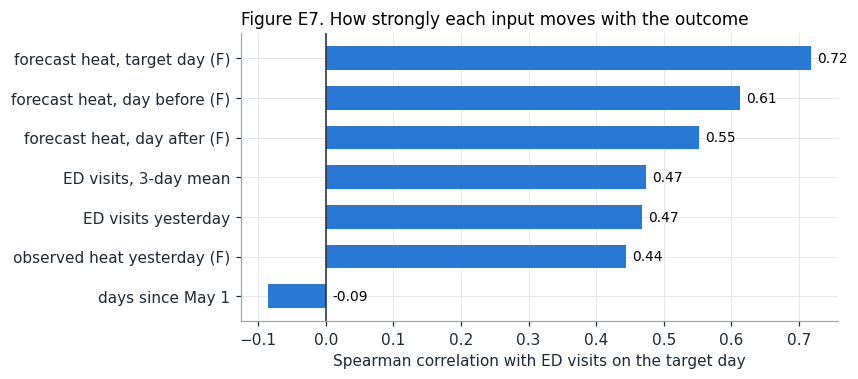

In [29]:
corr = d[FEATURES].corrwith(d["N_target"], method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh([labels[c] for c in corr.index], corr.values, color=BLUE, height=0.6)
for i, v in enumerate(corr.values):
    ax.annotate(f"{v:.2f}", (max(v, 0), i), xytext=(4, 0), textcoords="offset points",
                va="center", ha="left", fontsize=9)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Spearman correlation with ED visits on the target day")
ax.set_title("Figure E7. How strongly each input moves with the outcome", fontsize=11)
fig.savefig(FIG / "eda7_feature_correlations.png")
plt.show()

Spearman correlation is used instead of the usual (Pearson) correlation because the outcome is skewed. Spearman only looks at the ranking of values, so a few huge heat-wave days don't dominate it. The forecast heat for the target day has the strongest link, as expected. `day_of_season` is slightly negative here, but that does not mean it is useless: its effect is that the **same** heat causes more visits early in summer, which a one-variable correlation cannot show (Step 2's feature test found it matters).

## 8. Preprocessing: standardizing the inputs

### Why
The inputs are on very different scales: heat is around 85 ± 9 F, yesterday's ED visits around 5 ± 10, days since May 1 from 0 to 150. Logistic regression is fit with a penalty that shrinks large coefficients, and that penalty treats every coefficient the same. Without rescaling, inputs with big numbers get penalized differently from inputs with small numbers, purely because of their units.

### How
Each input is **standardized**: subtract its mean and divide by its standard deviation,

  z = (x − mean) / sd

so every input ends up with mean 0 and standard deviation 1. Standardizing changes the units, not the shape: the skewed ED inputs stay skewed, which is why their boxes in Figure E8 sit left of 0 with a long right tail. A z of +2 means "two standard deviations above a typical day", whatever the units.

### The rule that prevents leakage
The mean and standard deviation are learned from the **training seasons only**, then applied unchanged to the test season. If they were computed on all the data, a little information about the test season would leak into training. In the code this happens automatically: `models.logistic()` is a scikit-learn pipeline (`StandardScaler` then `LogisticRegression`), and the scaler is refit inside every training fold.

The example below fits the scaler on 2021-2024 and applies it to 2025.

In [30]:
from sklearn.preprocessing import StandardScaler

train, test = d[d["season"] <= 2024], d[d["season"] == 2025]
scaler = StandardScaler().fit(train[FEATURES])
z_train = pd.DataFrame(scaler.transform(train[FEATURES]), columns=FEATURES)
z_test = pd.DataFrame(scaler.transform(test[FEATURES]), columns=FEATURES)

pd.DataFrame({
    "training mean (learned)": scaler.mean_, "training sd (learned)": scaler.scale_,
    "after: train mean": z_train.mean().values, "after: train sd": z_train.std(ddof=0).values,
    "after: 2025 mean": z_test.mean().values, "after: 2025 sd": z_test.std(ddof=0).values,
}, index=[labels[c] for c in FEATURES]).round(2)

,training mean (learned),training sd (learned),after: train mean,after: train sd,after: 2025 mean,after: 2025 sd
"forecast heat, target day (F)",81.31,9.40,0.0,1.0,0.07,1.17
"forecast heat, day before (F)",81.24,9.52,0.0,1.0,0.09,1.15
"forecast heat, day after (F)",81.29,9.31,-0.0,1.0,0.10,1.15
ED visits yesterday,4.53,7.67,-0.0,1.0,0.51,2.34
"ED visits, 3-day mean",4.53,6.54,-0.0,1.0,0.59,2.33
observed heat yesterday (F),81.32,9.37,0.0,1.0,-0.07,1.09
days since May 1,77.89,42.88,-0.0,1.0,-0.20,0.92


After standardizing, the training seasons have mean 0 and sd 1 exactly. The 2025 test season does **not**, because its mean and sd were never used to fit the scaler. That is what we want: 2025 had more ED activity than the training years, and the scaled values honestly show it (positive means for the ED inputs).

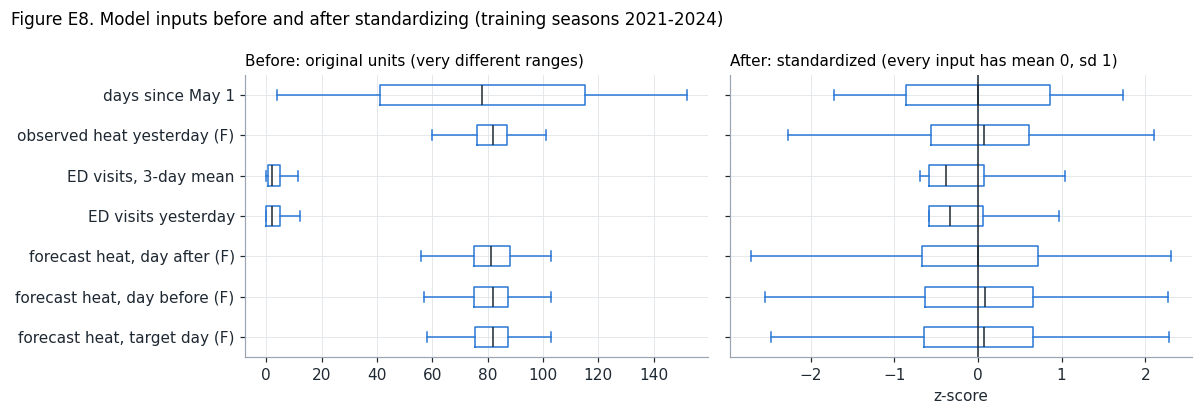

In [31]:
import warnings
warnings.filterwarnings("ignore", message=".*vert.*")  # newer matplotlib renames this option; works on old and new
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
box = dict(showfliers=False, vert=False, medianprops={"color": INK}, boxprops={"color": BLUE},
           whiskerprops={"color": BLUE}, capprops={"color": BLUE})
a1.boxplot([train[c] for c in FEATURES], **box)
a1.set_yticks(range(1, len(FEATURES) + 1), [labels[c] for c in FEATURES])
a1.set_title("Before: original units (very different ranges)")
a2.boxplot([z_train[c] for c in FEATURES], **box)
a2.set_yticks(range(1, len(FEATURES) + 1), [""] * len(FEATURES))
a2.axvline(0, color=INK, lw=1)
a2.set_title("After: standardized (every input has mean 0, sd 1)")
a2.set_xlabel("z-score")
fig.suptitle("Figure E8. Model inputs before and after standardizing (training seasons 2021-2024)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "eda8_standardization.png")
plt.show()

### What is *not* done, and why

| Not done | Reason |
|---|---|
| Fill in missing values (imputation) | Only about 5% of rows are affected, and filling in ED counts would invent the outcome |
| Remove outliers | The extreme days are real heat waves, the very events the model must catch |
| Transform the outcome | The model predicts a yes/no (high-burden day or not), so the skew of N does not need fixing |
| Encode categories | All inputs are already numbers |
| Log-transform skewed inputs (ED lags) | Possible, and worth testing later; standardizing is enough for a first model |

## 9. Key takeaways from Step 1

1. **Data are complete enough.** 10 of 1,530 ED days and a handful of forecast runs are missing. About 5% of decision rows (42 of 911) are dropped, with no filling in.
2. **The outcome is skewed and imbalanced:** most days have 0-5 visits, heat waves have 50-150, and only about 1 in 10 decision days is high-burden.
3. **Visits rise steeply from about 85-90 F,** before the current 95 F rule kicks in (Figure E3).
4. **The 1-day forecast is good but not perfect:** a mean absolute error of a few degrees near the 90-100 F decision range, which matters when a rule hinges on one number.
5. **Some high-burden days had no NWS alert** (Figure E6). These are the misses a better rule could catch.
6. **Inputs are standardized** using training-season statistics only, inside the model pipeline.